# **Parte 3.1: Clasificación**

7. Clasificación:
    - Escoge una variable objetivo categórica relevante.
    - Codifica adecuadamente las variables predictoras.
    - Divide el dataset en 70% entrenamiento y 30% prueba.
    - Ajusta los siguientes modelos:
        - Regresión logística
        - Naive Bayes
        - SVM
    - Evalúa con:
        - Matriz de confusión
        - Precisión y recall
        - Curva ROC y AUC
        - Importancia de variables
    - **Compara el desempeño de todos los modelos.**

### **0: Dependencias**

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay, confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, roc_auc_score
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Carpeta donde se guardan las figuras (se reutilizan en el reporte en PDF)
FIG_DIR = "/home/yagoh/Escritorio/Personal/dev/Educacion/Diplomado-Tecnicas-Estadisticas-y-Mineria-de-Datos/Unidad_3/Tarea/Documentos/Practica_3/figures/"


### **1. Variable objetivo**

##### 1.1: Carga del dataset limpio

In [2]:
# Usamos el dataset que resultó de la Práctica Integradora (ya sin duplicados y con NAs/outliers tratados)
path = "/home/yagoh/Escritorio/Personal/dev/Educacion/Diplomado-Tecnicas-Estadisticas-y-Mineria-de-Datos/Unidad_3/Data/Practicas/Netflix_clean.csv"
df = pd.read_csv(path)

print(f"El dataset tiene {df.shape[0]:,} observaciones y {df.shape[1]} variables.")
df.head(1)

El dataset tiene 15,330 observaciones y 31 variables.


,Title,Genre,Tags,Languages,Series or Movie,Hidden Gem Score,Country Availability,Runtime,Director,Writer,...,Netflix Link,IMDb Link,Summary,IMDb Votes,Image,Poster,TMDb Trailer,Trailer Site,IMDb Votes_log,Boxoffice_log
0,Lets Fight Ghost,"Crime, Drama, Fantasy, Horror, Romance","Comedy Programmes,Romantic TV Comedies,Horror ...","Swedish, Spanish",Series,4.3,Thailand,< 30 minutes,Tomas Alfredson,John Ajvide Lindqvist,...,https://www.netflix.com/watch/81415947,https://www.imdb.com/title/tt1139797,A med student with a supernatural gift tries t...,205926.0,https://occ-0-4708-64.1.nflxso.net/dnm/api/v6/...,https://m.media-amazon.com/images/M/MV5BOWM4NT...,NaN,NaN,12.235277,14.567901


##### 1.2: Escoge una variable objetivo categórica relevante

Propongo como variable objetivo **`Series or Movie`**: ¿un título del catálogo es una **serie** o una **película**? Es relevante porque la plataforma planea, produce y recomienda de forma distinta cada formato, y además:
- Es **binaria** y no tiene valores faltantes, por lo que no hay que imputar la etiqueta.
- Está **desbalanceada**, lo que nos obliga a ir más allá del *accuracy* y a usar precisión, recall y AUC.

Definimos **Series = 1 (clase positiva)** y **Movie = 0**.

                 Títulos     %
Series or Movie               
Movie              11590  75.6
Series              3740  24.4


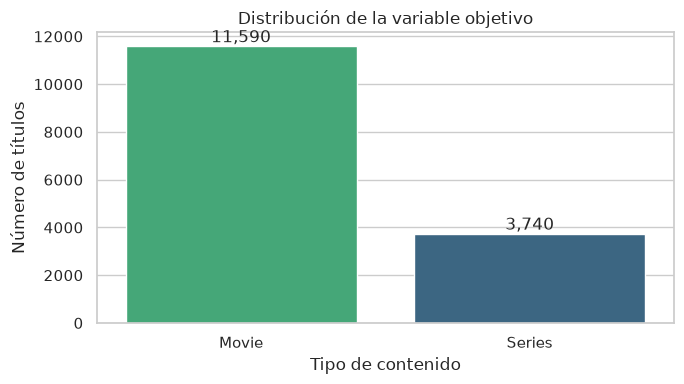

In [3]:
y = (df["Series or Movie"] == "Series").astype(int)

conteo = df["Series or Movie"].value_counts()
print(pd.DataFrame({"Títulos": conteo, "%": (conteo / len(df) * 100).round(2)}))

plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x="Series or Movie", order=conteo.index, hue="Series or Movie", palette="viridis", legend=False)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Distribución de la variable objetivo")
plt.xlabel("Tipo de contenido")
plt.ylabel("Número de títulos")
plt.tight_layout()
plt.savefig(FIG_DIR + "p3_1_objetivo.png", dpi=150)
plt.show()

- Hay **11,590 películas (75.6%)** y **3,740 series (24.4%)**: aproximadamente 3 a 1.
- Un modelo que siempre dijera "película" tendría 75.6% de *accuracy* sin aprender nada, por eso el *accuracy* por sí solo no sirve y se evaluará con precisión, recall, F1 y AUC.

##### 1.3: ¿Hay alguna variable que "delate" el objetivo? (fuga de información)

In [4]:
# Antes de elegir predictoras, revisemos si alguna variable explica casi por completo a la variable objetivo.
tabla_runtime = pd.crosstab(df["Runtime"], df["Series or Movie"], margins=True)
tabla_runtime["% Series"] = (tabla_runtime["Series"] / tabla_runtime["All"] * 100).round(2)
tabla_runtime

Series or Movie,Movie,Series,All,% Series
Runtime,,,,
1-2 hour,9044,0,9044,0.00
30-60 mins,333,0,333,0.00
< 30 minutes,214,3739,3953,94.59
> 2 hrs,1999,0,1999,0.00
All,11590,3739,15329,24.39


- **`Runtime` delata casi por completo la clase**: ninguna serie dura más de 30 minutos en esta variable (para series mide la duración del episodio) y el 100% de los títulos de `30-60 mins`, `1-2 hour` y `> 2 hrs` son películas. Solo `< 30 minutes` mezcla ambas clases (94.6% series).
- Si la incluimos, el problema se vuelve casi trivial (se verá en 7.5). Por eso se **excluye de la comparación principal** y se usa solo como análisis de sensibilidad.
- La tabla suma 15,329 títulos porque hay 1 valor faltante en `Runtime`.

### **2. Codificación de las variables predictoras**

Se evitan las variables que son identificadores o texto libre (`Title`, `Netflix Link`, `IMDb Link`, `Summary`, `Image`, `Poster`, `TMDb Trailer`...), las que tienen más de ~50% de NAs (`Boxoffice`, `Metacritic Score`, `Rotten Tomatoes Score`, `Awards *`, `Production House`) y `Runtime` por la fuga de información que vimos en 1.3 (se retoma como análisis de sensibilidad en la sección 7).

In [5]:
X = pd.DataFrame(index=df.index)

# --- Numéricas (ya limpias desde la Práctica Integradora) ---
X["Hidden Gem Score"] = df["Hidden Gem Score"]
X["IMDb Score"] = df["IMDb Score"]
X["IMDb Votes (log)"] = df["IMDb Votes_log"]        # versión logarítmica por la asimetría

# --- Numéricas derivadas ---
X["Año en Netflix"] = pd.to_datetime(df["Netflix Release Date"], errors="coerce").dt.year
X["N° géneros"] = df["Genre"].fillna("").apply(lambda s: len([g for g in s.split(", ") if g]))
X["N° idiomas"] = df["Languages"].fillna("").apply(lambda s: len([i for i in s.split(", ") if i]))

# --- Binaria: ¿está disponible en inglés? ---
X["Idioma: English"] = df["Languages"].fillna("").str.contains("English").astype(int)

# --- Multi-hot: top 12 géneros (un título puede tener varios) ---
top_generos = df["Genre"].dropna().str.split(", ").explode().value_counts().head(12).index
lista_generos = df["Genre"].fillna("").str.split(", ")
for g in top_generos:
    X[f"Género: {g}"] = lista_generos.apply(lambda lst: int(g in lst))

# --- One-hot: clasificación por edad (los NaN se vuelven una categoría propia) ---
view_rating = df["View Rating"].fillna("Desconocido")
for r in view_rating.value_counts().index:
    X[f"Rating: {r}"] = (view_rating == r).astype(int)

print(f"Matriz de predictoras: {X.shape[0]:,} filas x {X.shape[1]} columnas")
print(f"NAs restantes en X: {X.isna().sum().sum()}")

Matriz de predictoras: 15,330 filas x 48 columnas
NAs restantes en X: 0


In [6]:
# Resumen de cómo se codificó cada grupo de variables
pd.DataFrame({
    "Grupo": ["Numéricas originales", "Numéricas derivadas", "Binaria", "Multi-hot (Genre)", "One-hot (View Rating)"],
    "Variables": [3, 3, 1, len(top_generos), view_rating.nunique()],
    "Codificación": ["Se usan tal cual (+ estandarización)", "Conteos y año a partir de texto/fecha",
                     "1 si contiene 'English'", "Una columna 0/1 por género frecuente", "Una columna 0/1 por categoría (NaN = Desconocido)"],
})

,Grupo,Variables,Codificación
0,Numéricas originales,3,Se usan tal cual (+ estandarización)
1,Numéricas derivadas,3,Conteos y año a partir de texto/fecha
2,Binaria,1,1 si contiene 'English'
3,Multi-hot (Genre),12,Una columna 0/1 por género frecuente
4,One-hot (View Rating),29,Una columna 0/1 por categoría (NaN = Desconocido)


- Quedan **48 predictoras sin NAs**: 6 numéricas, 1 binaria, 12 géneros multi-hot y 29 categorías de `View Rating`.
- Los NaN de `View Rating` (45.6% del dataset) se conservaron como la categoría **`Desconocido`** en lugar de imputarlos: que falte la clasificación por edad puede ser informativo y no se inventa un valor.
- Los géneros se codifican *multi-hot* porque un título puede tener varios; `Languages` se resume en un indicador de inglés y un conteo de idiomas para no crear cientos de columnas.

### **3. División en entrenamiento (70%) y prueba (30%)**

In [7]:
# Estratificamos por la variable objetivo para conservar la proporción de series y películas en ambos conjuntos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)

print(f"Entrenamiento: {X_train.shape[0]:,} filas ({X_train.shape[0] / len(X):.0%})")
print(f"Prueba:        {X_test.shape[0]:,} filas ({X_test.shape[0] / len(X):.0%})")
print(f"\n% de Series -> total: {y.mean():.2%} | train: {y_train.mean():.2%} | test: {y_test.mean():.2%}")

Entrenamiento: 10,731 filas (70%)
Prueba:        4,599 filas (30%)

% de Series -> total: 24.40% | train: 24.40% | test: 24.40%


La estandarización (`StandardScaler`) se incluye dentro de un `Pipeline` para cada modelo, de modo que la media y la desviación estándar se calculen **solo con entrenamiento** y no haya fuga de información hacia prueba. Además, definimos funciones auxiliares para evaluar los tres modelos exactamente igual.

In [8]:
resultados = {}      # métricas por modelo
curvas_roc = {}      # (fpr, tpr, auc) por modelo
importancias = {}    # importancia por permutación por modelo
predicciones = {}    # predicciones sobre prueba por modelo

def puntajes(modelo, X_):
    """Puntaje de la clase positiva: probabilidad si existe, si no la función de decisión (SVM)."""
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X_)[:, 1]
    return modelo.decision_function(X_)

def graficar_matriz(nombre, archivo):
    y_pred = predicciones[nombre]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Movie", "Series"],
                                            cmap="Blues", ax=axes[0], colorbar=False)
    axes[0].set_title("Conteos")
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Movie", "Series"],
                                            normalize="true", values_format=".1%",
                                            cmap="Blues", ax=axes[1], colorbar=False)
    axes[1].set_title("Normalizada por fila (recall)")
    for ax in axes:
        ax.grid(False)
    plt.suptitle(f"Matriz de confusión: {nombre}", y=1.02)
    plt.tight_layout()
    plt.savefig(FIG_DIR + archivo, dpi=150, bbox_inches="tight")
    plt.show()

def calcular_metricas(nombre):
    y_pred = predicciones[nombre]
    resultados[nombre] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "AUC": curvas_roc[nombre][2],
    }
    print(classification_report(y_test, y_pred, target_names=["Movie", "Series"], digits=3))

def graficar_roc(nombre, archivo, color):
    fpr, tpr, auc = curvas_roc[nombre]
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, color=color, lw=2, label=f"{nombre} (AUC = {auc:.3f})")
    plt.plot([0, 1], [0, 1], "k--", lw=1, label="Azar (AUC = 0.5)")
    plt.xlabel("Tasa de falsos positivos (1 - especificidad)")
    plt.ylabel("Tasa de verdaderos positivos (recall)")
    plt.title(f"Curva ROC: {nombre}")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig(FIG_DIR + archivo, dpi=150)
    plt.show()

def graficar_importancia(nombre, archivo, color, top=15):
    imp = importancias[nombre].head(top).iloc[::-1]
    plt.figure(figsize=(8, 6))
    plt.barh(imp.index, imp["media"], xerr=imp["std"], color=color)
    plt.xlabel("Caída del AUC al permutar la variable (en prueba)")
    plt.title(f"Importancia de variables por permutación: {nombre}")
    plt.tight_layout()
    plt.savefig(FIG_DIR + archivo, dpi=150)
    plt.show()

def evaluar(nombre, modelo):
    """Calcula predicciones, ROC e importancia por permutación sobre el conjunto de prueba."""
    predicciones[nombre] = modelo.predict(X_test)
    fpr, tpr, _ = roc_curve(y_test, puntajes(modelo, X_test))
    curvas_roc[nombre] = (fpr, tpr, roc_auc_score(y_test, puntajes(modelo, X_test)))
    perm = permutation_importance(modelo, X_test, y_test, scoring="roc_auc",
                                  n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    importancias[nombre] = (pd.DataFrame({"media": perm.importances_mean, "std": perm.importances_std},
                                         index=X.columns).sort_values("media", ascending=False))

### **4. Regresión logística**

##### 4.1: Ajuste del modelo

In [9]:
# class_weight="balanced" penaliza más los errores en la clase minoritaria (Series)
modelo_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
])
modelo_lr.fit(X_train, y_train)
evaluar("Regresión logística", modelo_lr)

print(f"Accuracy en entrenamiento: {modelo_lr.score(X_train, y_train):.3f}")
print(f"Accuracy en prueba:        {modelo_lr.score(X_test, y_test):.3f}")

Accuracy en entrenamiento: 0.729
Accuracy en prueba:        0.724


##### 4.2: Matriz de confusión

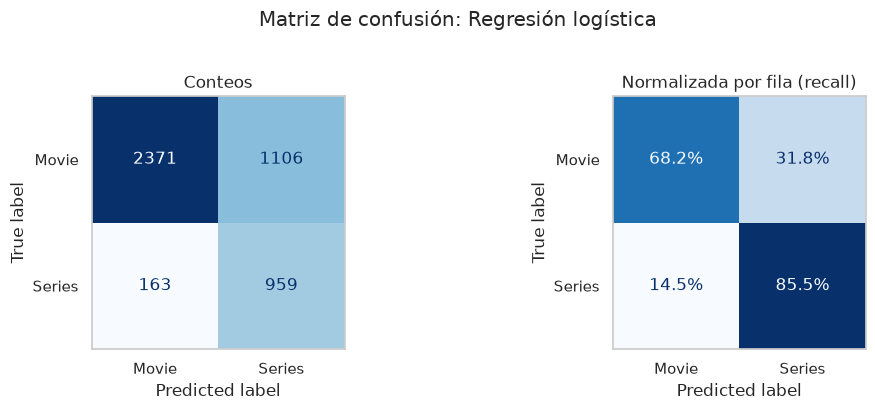

In [10]:
graficar_matriz("Regresión logística", "p3_4_lr_matriz.png")

##### 4.3: Precisión y recall

In [11]:
calcular_metricas("Regresión logística")

              precision    recall  f1-score   support

       Movie      0.936     0.682     0.789      3477
      Series      0.464     0.855     0.602      1122

    accuracy                          0.724      4599
   macro avg      0.700     0.768     0.695      4599
weighted avg      0.821     0.724     0.743      4599



##### 4.4: Curva ROC y AUC

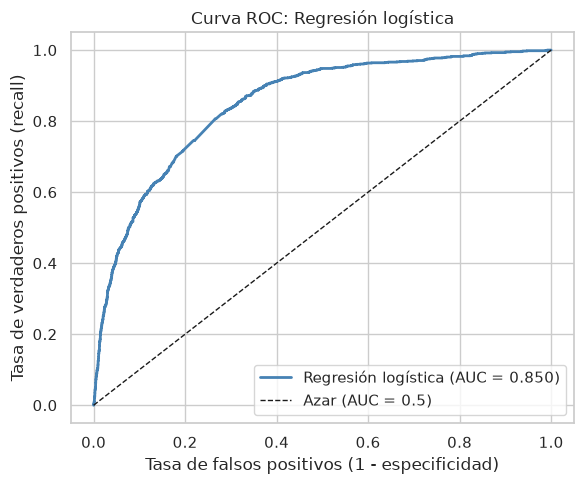

In [12]:
graficar_roc("Regresión logística", "p3_4_lr_roc.png", "steelblue")

##### 4.5: Importancia de variables

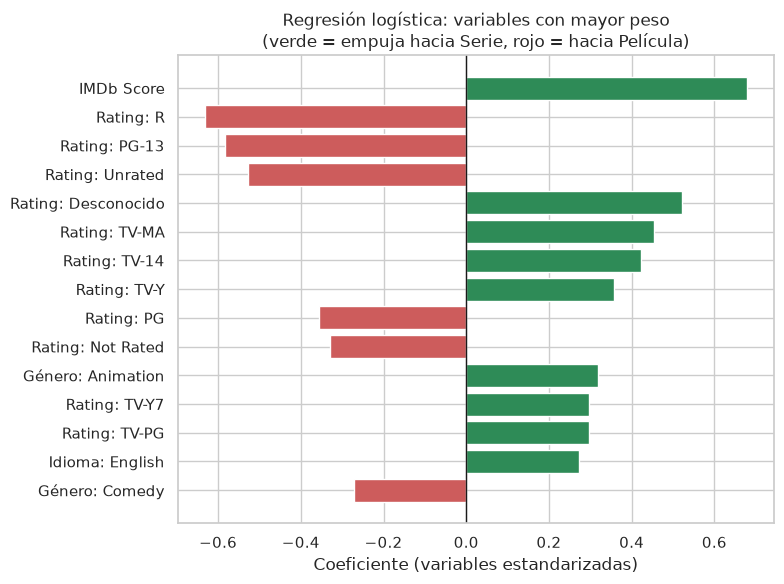

,Coeficiente,Odds ratio
IMDb Score,0.679,1.971
Rating: R,-0.632,0.532
Rating: PG-13,-0.582,0.559
Rating: Unrated,-0.528,0.590
Rating: Desconocido,0.523,1.687
Rating: TV-MA,0.454,1.575
Rating: TV-14,0.422,1.525
Rating: TV-Y,0.358,1.430
Rating: PG,-0.356,0.700
Rating: Not Rated,-0.330,0.719


In [13]:
# En regresión logística, los coeficientes (con variables estandarizadas) indican el efecto de +1 desviación estándar
# sobre el log-odds de ser Serie. exp(coef) es el odds ratio.
coefs = pd.Series(modelo_lr.named_steps["clf"].coef_[0], index=X.columns)
top_coefs = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15).iloc[::-1]

plt.figure(figsize=(8, 6))
plt.barh(top_coefs.index, top_coefs.values, color=np.where(top_coefs.values > 0, "seagreen", "indianred"))
plt.axvline(0, color="k", lw=1)
plt.xlabel("Coeficiente (variables estandarizadas)")
plt.title("Regresión logística: variables con mayor peso\n(verde = empuja hacia Serie, rojo = hacia Película)")
plt.tight_layout()
plt.savefig(FIG_DIR + "p3_4_lr_coeficientes.png", dpi=150)
plt.show()

pd.DataFrame({"Coeficiente": top_coefs[::-1], "Odds ratio": np.exp(top_coefs[::-1])}).round(3)

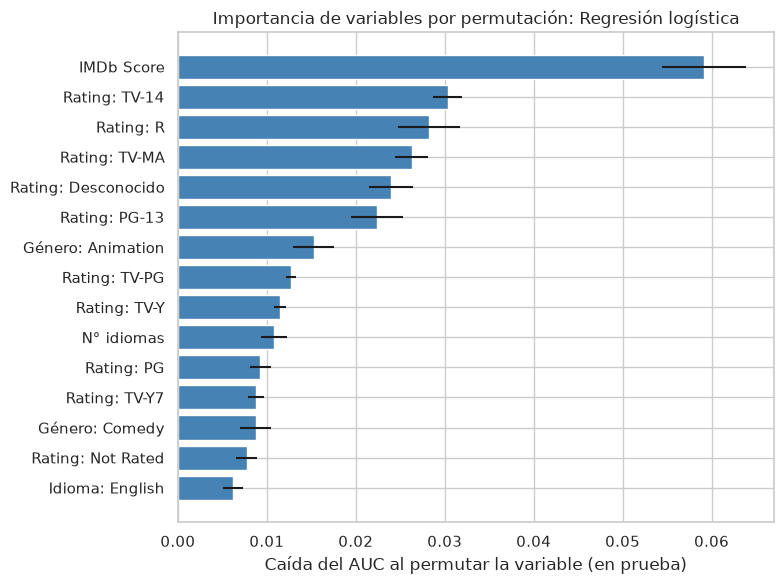

In [14]:
# Para poder comparar los tres modelos con el mismo criterio, también calculamos la importancia por permutación
graficar_importancia("Regresión logística", "p3_4_lr_permutacion.png", "steelblue")

- **Matriz de confusión:** de 1,122 series de prueba acertó 959 (recall 85.5%), pero clasificó como serie a 1,106 películas (de 3,477), por lo que la **precisión de la clase Series es solo 46.4%**. Con `class_weight="balanced"` el modelo prefiere no perder series a costa de falsas alarmas.
- **AUC = 0.850:** buena capacidad de separar las clases, mejor que el azar (0.5). Accuracy de 0.729 en entrenamiento vs. 0.724 en prueba: **no hay sobreajuste**.
- **Variables más importantes:** `IMDb Score` (+1 desv. est. multiplica por 1.97 los odds de ser serie), las clasificaciones de cine `R` y `PG-13` (odds ×0.53 y ×0.56, empujan hacia película) y las de TV `TV-MA`/`TV-14` (×1.58 y ×1.53, hacia serie). Tener `View Rating` desconocido también aumenta los odds de ser serie (×1.69), y `Animation` e `Idioma: English` suman a favor de serie.

### **5. Naive Bayes**

##### 5.1: Ajuste del modelo

In [15]:
# GaussianNB asume que cada variable, dada la clase, es normal e independiente de las demás.
# No tiene hiperparámetros relevantes, así que se usa con los valores por defecto.
modelo_nb = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", GaussianNB()),
])
modelo_nb.fit(X_train, y_train)
evaluar("Naive Bayes", modelo_nb)

print(f"Accuracy en entrenamiento: {modelo_nb.score(X_train, y_train):.3f}")
print(f"Accuracy en prueba:        {modelo_nb.score(X_test, y_test):.3f}")
print(f"Probabilidades a priori (Movie, Series): {modelo_nb.named_steps['clf'].class_prior_.round(3)}")

Accuracy en entrenamiento: 0.590
Accuracy en prueba:        0.589
Probabilidades a priori (Movie, Series): [0.756 0.244]


##### 5.2: Matriz de confusión

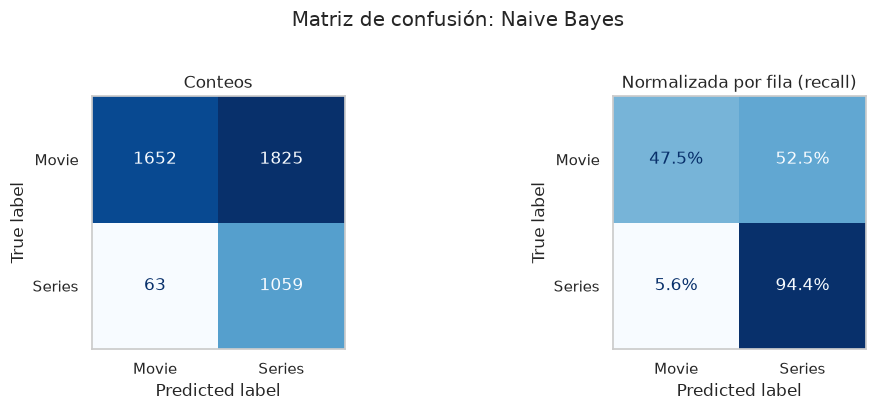

In [16]:
graficar_matriz("Naive Bayes", "p3_5_nb_matriz.png")

##### 5.3: Precisión y recall

In [17]:
calcular_metricas("Naive Bayes")

              precision    recall  f1-score   support

       Movie      0.963     0.475     0.636      3477
      Series      0.367     0.944     0.529      1122

    accuracy                          0.589      4599
   macro avg      0.665     0.709     0.583      4599
weighted avg      0.818     0.589     0.610      4599



##### 5.4: Curva ROC y AUC

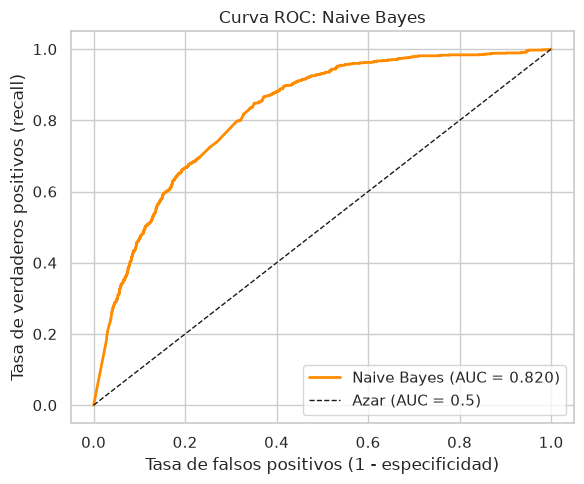

In [18]:
graficar_roc("Naive Bayes", "p3_5_nb_roc.png", "darkorange")

##### 5.5: Importancia de variables

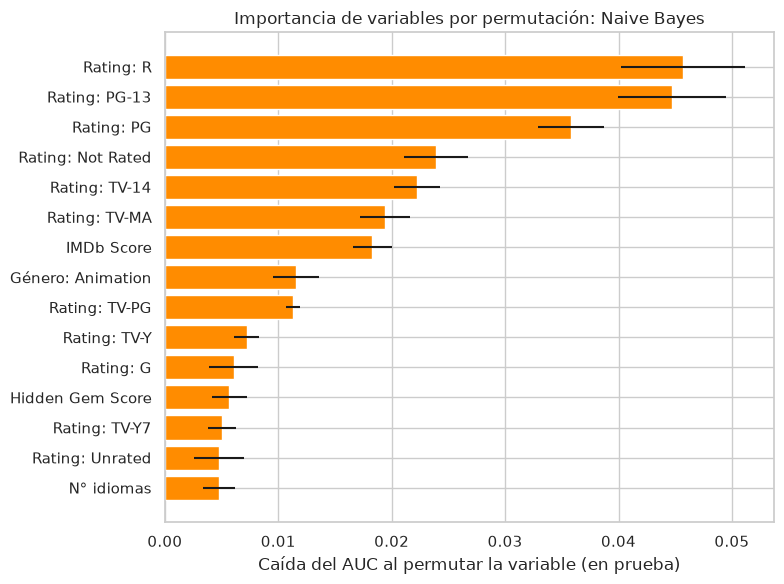

In [19]:
# Naive Bayes no tiene coeficientes, así que usamos la importancia por permutación sobre el conjunto de prueba:
# cuánto cae el AUC cuando se "revuelven" los valores de una variable.
graficar_importancia("Naive Bayes", "p3_5_nb_permutacion.png", "darkorange")

In [20]:
# Como complemento: diferencia de medias estandarizada entre clases que "ve" el modelo (theta_ = media por clase)
clf_nb = modelo_nb.named_steps["clf"]
dif = pd.Series((clf_nb.theta_[1] - clf_nb.theta_[0]) / np.sqrt(clf_nb.var_.mean(axis=0)), index=X.columns)
dif.reindex(dif.abs().sort_values(ascending=False).index).head(8).round(3).to_frame("Series - Movie (en desv. est.)")

,Series - Movie (en desv. est.)
IMDb Score,0.639
Hidden Gem Score,0.576
Rating: R,-0.575
Género: Animation,0.467
Rating: PG-13,-0.466
Rating: TV-14,0.395
Rating: Not Rated,-0.390
Rating: TV-MA,0.361


- **Matriz de confusión:** es el modelo con **mayor recall (94.4%)**: solo se le escapan 63 series, pero etiqueta como serie a 1,825 películas, así que la precisión cae a **36.7%** y el accuracy a 0.589. Casi la mitad de las películas queda mal clasificada.
- **AUC = 0.820:** el más bajo de los tres. Su ranking de probabilidades también es peor, no solo el umbral.
- **Por qué rinde menos:** el supuesto de independencia entre variables se viola (los ratings, géneros e idiomas están relacionados) y varias predictoras son binarias, no normales. Esto produce probabilidades extremas y mal calibradas.
- **Variables más importantes:** a diferencia de los otros modelos, depende sobre todo de las clasificaciones de cine (`R`, `PG-13`, `PG`) y menos de `IMDb Score`.

### **6. SVM (Máquina de Vectores de Soporte)**

##### 6.1: Ajuste del modelo

In [21]:
# Kernel RBF con búsqueda de hiperparámetros (C y gamma) mediante validación cruzada de 3 pliegues SOLO sobre entrenamiento.
# Se optimiza el AUC para no depender de un umbral fijo.
pipe_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE)),
])
param_grid = {"clf__C": [1, 5, 20], "clf__gamma": [0.001, 0.005, 0.02]}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

busqueda = GridSearchCV(pipe_svm, param_grid, scoring="roc_auc", cv=cv, n_jobs=-1)
busqueda.fit(X_train, y_train)

modelo_svm = busqueda.best_estimator_
print(f"Mejores hiperparámetros: {busqueda.best_params_}")
print(f"AUC medio en validación cruzada: {busqueda.best_score_:.4f}")
evaluar("SVM", modelo_svm)

print(f"\nAccuracy en entrenamiento: {modelo_svm.score(X_train, y_train):.3f}")
print(f"Accuracy en prueba:        {modelo_svm.score(X_test, y_test):.3f}")
print(f"Vectores de soporte: {modelo_svm.named_steps['clf'].n_support_.sum():,} de {len(X_train):,} observaciones")

Mejores hiperparámetros: {'clf__C': 20, 'clf__gamma': 0.005}
AUC medio en validación cruzada: 0.8579



Accuracy en entrenamiento: 0.770


Accuracy en prueba:        0.747
Vectores de soporte: 5,252 de 10,731 observaciones


In [22]:
# Resultados de toda la rejilla de búsqueda
(pd.DataFrame(busqueda.cv_results_)[["param_clf__C", "param_clf__gamma", "mean_test_score", "rank_test_score"]]
   .sort_values("rank_test_score").round(4).reset_index(drop=True))

,param_clf__C,param_clf__gamma,mean_test_score,rank_test_score
0,20,0.005,0.8579,1
1,5,0.005,0.8554,2
2,1,0.020,0.8535,3
3,20,0.001,0.8513,4
4,5,0.020,0.8512,5
5,1,0.005,0.8506,6
6,1,0.001,0.8496,7
7,5,0.001,0.8462,8
8,20,0.020,0.8418,9


##### 6.2: Matriz de confusión

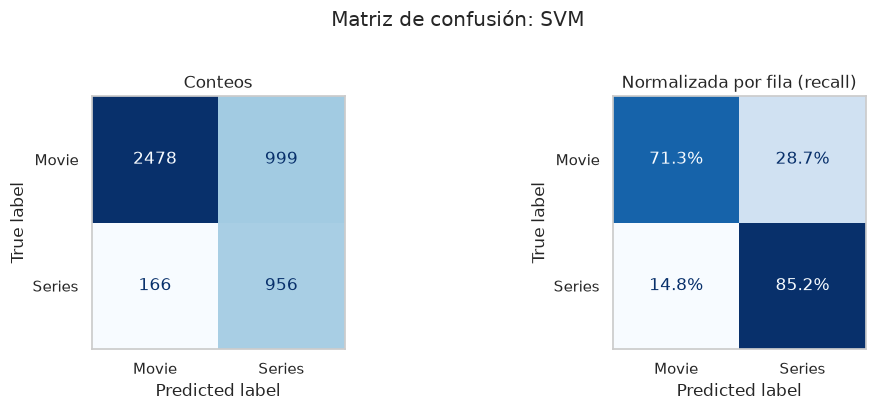

In [23]:
graficar_matriz("SVM", "p3_6_svm_matriz.png")

##### 6.3: Precisión y recall

In [24]:
calcular_metricas("SVM")

              precision    recall  f1-score   support

       Movie      0.937     0.713     0.810      3477
      Series      0.489     0.852     0.621      1122

    accuracy                          0.747      4599
   macro avg      0.713     0.782     0.716      4599
weighted avg      0.828     0.747     0.764      4599



##### 6.4: Curva ROC y AUC

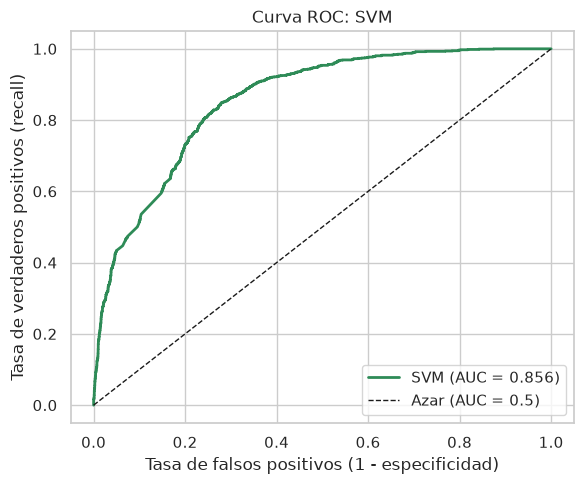

In [25]:
# El SVM no entrega probabilidades de forma directa; para la ROC se usa la función de decisión (distancia al hiperplano).
graficar_roc("SVM", "p3_6_svm_roc.png", "seagreen")

##### 6.5: Importancia de variables

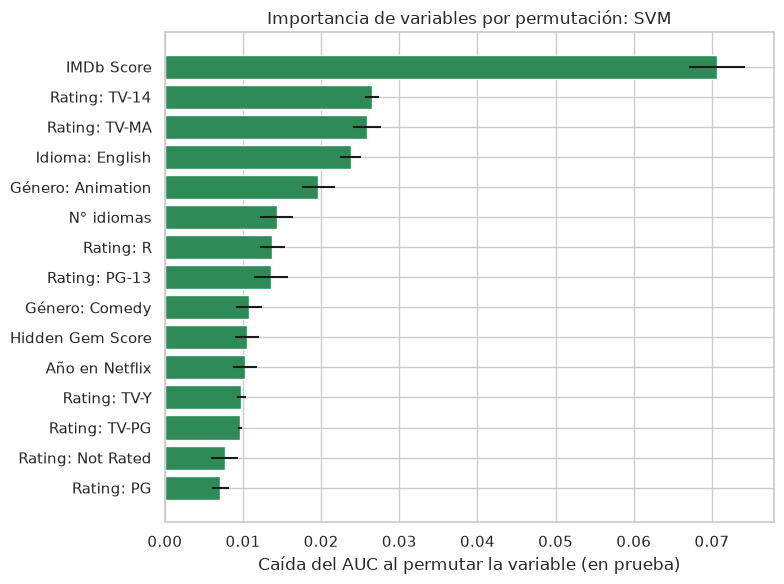

In [26]:
# Con kernel RBF no hay coeficientes interpretables, por lo que se usa la importancia por permutación.
graficar_importancia("SVM", "p3_6_svm_permutacion.png", "seagreen")

- **Hiperparámetros:** la mejor combinación fue `C=20`, `gamma=0.005` (AUC en validación cruzada = 0.858). Las diferencias entre combinaciones son pequeñas (0.842 a 0.858): el modelo es poco sensible al ajuste. Al ser el mejor valor de `C` el borde de la rejilla, un `C` mayor podría ganar muy poco.
- **Matriz de confusión:** acierta 956 de 1,122 series (recall 85.2%) y comete 999 falsos positivos, la menor cantidad de los tres. Precisión de 48.9%, F1 de 0.621 y accuracy de 0.747.
- **AUC = 0.856:** el más alto. Accuracy de 0.770 en entrenamiento vs. 0.747 en prueba: ligera diferencia, sin sobreajuste severo. Usa 5,252 vectores de soporte (casi la mitad de los datos), lo que indica una frontera compleja.
- **Variables más importantes:** `IMDb Score` destaca claramente (caída de ~0.07 de AUC al permutarla), seguida de `TV-14`, `TV-MA`, `Idioma: English` y `Animation`.

### **7. Comparación de modelos**

##### 7.1: Tabla comparativa de métricas (conjunto de prueba)

In [27]:
tabla = pd.DataFrame(resultados).T[["Accuracy", "Precision", "Recall", "F1", "AUC"]]
tabla.style.format("{:.3f}").highlight_max(axis=0, color="lightgreen")

,Accuracy,Precision,Recall,F1,AUC
Regresión logística,0.724,0.464,0.855,0.602,0.850
Naive Bayes,0.589,0.367,0.944,0.529,0.820
SVM,0.747,0.489,0.852,0.621,0.856


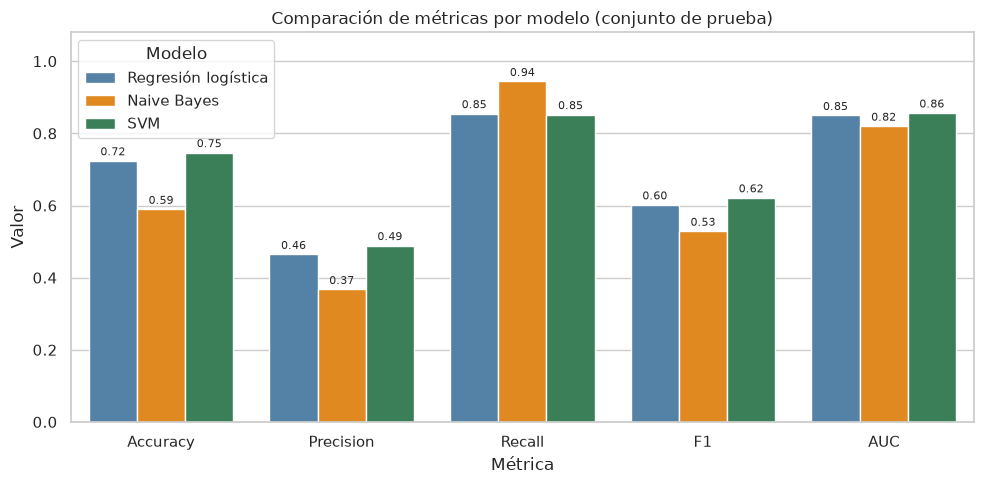

In [28]:
# Gráfica de barras agrupadas de las métricas
tabla_larga = tabla.reset_index(names="Modelo").melt(id_vars="Modelo", var_name="Métrica", value_name="Valor")
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=tabla_larga, x="Métrica", y="Valor", hue="Modelo", palette=["steelblue", "darkorange", "seagreen"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8, padding=2)
plt.ylim(0, 1.08)
plt.title("Comparación de métricas por modelo (conjunto de prueba)")
plt.tight_layout()
plt.savefig(FIG_DIR + "p3_7_metricas.png", dpi=150)
plt.show()

##### 7.2: Curvas ROC conjuntas

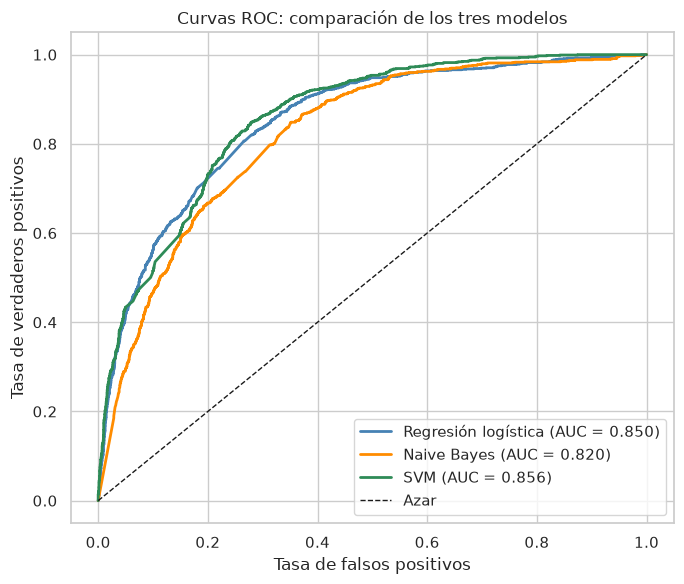

In [29]:
colores = {"Regresión logística": "steelblue", "Naive Bayes": "darkorange", "SVM": "seagreen"}
plt.figure(figsize=(7, 6))
for nombre, (fpr, tpr, auc) in curvas_roc.items():
    plt.plot(fpr, tpr, lw=2, color=colores[nombre], label=f"{nombre} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Azar")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curvas ROC: comparación de los tres modelos")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR + "p3_7_roc_conjunta.png", dpi=150)
plt.show()

##### 7.3: Matrices de confusión lado a lado

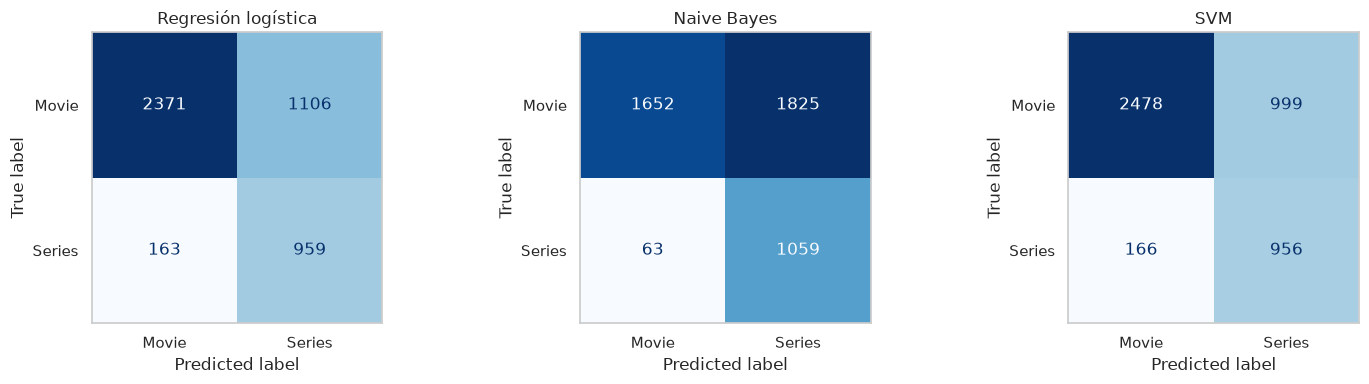

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, nombre in zip(axes, predicciones):
    ConfusionMatrixDisplay.from_predictions(y_test, predicciones[nombre], display_labels=["Movie", "Series"],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(nombre)
    ax.grid(False)
plt.tight_layout()
plt.savefig(FIG_DIR + "p3_7_matrices.png", dpi=150)
plt.show()

##### 7.4: Importancia de variables: ¿coinciden los modelos?

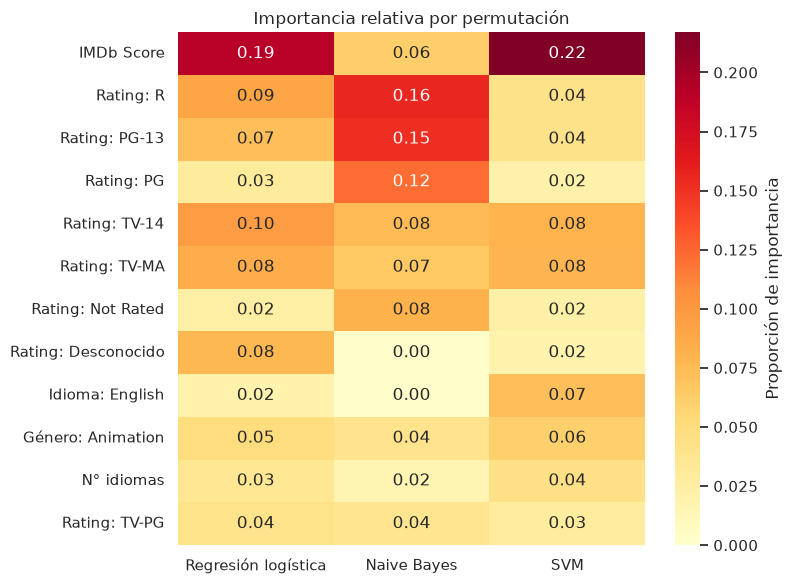

In [31]:
# Importancia por permutación normalizada (cada modelo suma 1) para las variables más relevantes en al menos un modelo
imp_df = pd.DataFrame({n: importancias[n]["media"] for n in importancias})
imp_norm = imp_df.clip(lower=0) / imp_df.clip(lower=0).sum()
top_vars = imp_norm.max(axis=1).sort_values(ascending=False).head(12).index

plt.figure(figsize=(8, 6))
sns.heatmap(imp_norm.loc[top_vars], annot=True, fmt=".2f", cmap="YlOrRd", cbar_kws={"label": "Proporción de importancia"})
plt.title("Importancia relativa por permutación")
plt.tight_layout()
plt.savefig(FIG_DIR + "p3_7_importancia.png", dpi=150)
plt.show()

##### 7.5: Análisis de sensibilidad: ¿qué pasa si incluimos `Runtime`?

In [32]:
# Reentrenamos los tres modelos agregando Runtime como variable ordinal (0 = < 30 min ... 3 = > 2 hrs)
X_rt = X.copy()
X_rt["Runtime"] = df["Runtime"].map({"< 30 minutes": 0, "30-60 mins": 1, "1-2 hour": 2, "> 2 hrs": 3}).fillna(2)
Xr_train, Xr_test, _, _ = train_test_split(X_rt, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)

params_svm = {k.replace("clf__", ""): v for k, v in busqueda.best_params_.items()}
modelos_rt = {
    "Regresión logística": Pipeline([("scaler", StandardScaler()),
                                     ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE))]),
    "Naive Bayes": Pipeline([("scaler", StandardScaler()), ("clf", GaussianNB())]),
    "SVM": Pipeline([("scaler", StandardScaler()), ("clf", SVC(kernel="rbf", class_weight="balanced", **params_svm))]),
}

filas = []
for nombre, m in modelos_rt.items():
    m.fit(Xr_train, y_train)
    filas.append({"Modelo": nombre,
                  "AUC sin Runtime": resultados[nombre]["AUC"],
                  "AUC con Runtime": roc_auc_score(y_test, puntajes(m, Xr_test)),
                  "F1 sin Runtime": resultados[nombre]["F1"],
                  "F1 con Runtime": f1_score(y_test, m.predict(Xr_test))})
pd.DataFrame(filas).set_index("Modelo").style.format("{:.3f}")

,AUC sin Runtime,AUC con Runtime,F1 sin Runtime,F1 con Runtime
Modelo,,,,
Regresión logística,0.850,0.996,0.602,0.972
Naive Bayes,0.820,0.991,0.529,0.950
SVM,0.856,0.996,0.621,0.972


- Al incluir `Runtime` el AUC sube de ~0.85 a **0.996 (regresión logística y SVM) y 0.991 (Naive Bayes)**, y el F1 de ~0.60 a 0.97. Las diferencias entre modelos casi desaparecen, porque `Runtime` resuelve el problema por sí sola.
- Esto confirma que la comparación sin `Runtime` es la más informativa, ya que refleja qué tan bien los modelos aprovechan señales **de contenido** (calificaciones, género, idioma) para distinguir series de películas.

##### 7.6: Conclusión general de la comparación

| Criterio | Regresión logística | Naive Bayes | SVM |
|---|---|---|---|
| Accuracy | 0.724 | 0.589 | **0.747** |
| Precisión (Series) | 0.464 | 0.367 | **0.489** |
| Recall (Series) | 0.855 | **0.944** | 0.852 |
| F1 | 0.602 | 0.529 | **0.621** |
| AUC | 0.850 | 0.820 | **0.856** |

- **El SVM es el mejor en casi todas las métricas** (accuracy, precisión, F1 y AUC), pero su ventaja sobre la **regresión logística es pequeña** (AUC 0.856 vs. 0.850). Con casi la misma capacidad predictiva, la regresión logística es mucho más **rápida** (milisegundos vs. segundos más una búsqueda de hiperparámetros) e **interpretable** (odds ratios).
- **Naive Bayes es el más débil** en AUC, accuracy y precisión, y solo gana en recall (0.944) porque etiqueta casi todo como serie. Solo sería preferible si lo más importante fuera no perder ninguna serie.
- Los tres modelos coinciden en que **`IMDb Score` y la clasificación por edad (`View Rating`)** son las variables más informativas: el contenido de TV (`TV-MA`, `TV-14`) se asocia con series y el de cine (`R`, `PG-13`) con películas.
- **Limitación común:** la precisión de la clase Series no supera 0.49, es decir, más de la mitad de los títulos que se predicen como serie son películas. Esto se debe en parte al desbalance y al uso de `class_weight="balanced"` con el umbral por defecto; ajustar el umbral de decisión permitiría equilibrar precisión y recall según la necesidad de negocio.
- **Recomendación:** usar **SVM** si se busca el mayor desempeño, o **regresión logística** si se prioriza simplicidad e interpretabilidad con un costo mínimo en desempeño.